# 01 · Loss functions

**Goal:** understand what a loss is, build cross-entropy by hand, and see *why* it is the right loss for
classification. Everything here runs on CPU in seconds.

**The big picture.** A neural network turns an image into **logits**: one raw score per class
(e.g. 37 numbers for the 37 pet breeds). The **loss** compares those scores with the true label and returns
*one number*: "how wrong was the model?". Training = repeatedly changing the weights to push that number down.

Run the cells top to bottom. Each section ends with **What to observe** and the notebook ends with exercises.

In [1]:
import sys, pathlib

# Make `import src...` work whether this notebook is opened from learn/ or from the repo root.
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("torch", torch.__version__, "| repo root:", ROOT)
from src.losses import softmax, cross_entropy_from_scratch, FocalLoss, build_loss, LOSS_NAMES
import torch.nn as nn
import torch.nn.functional as F
print("losses available in src/losses.py:", LOSS_NAMES)

torch 2.15.0+cpu | repo root: D:\ali\Programming\D&D
losses available in src/losses.py: ('cross_entropy', 'label_smoothing', 'focal')


## 1. From scores to probabilities: softmax

Logits can be any real number. **Softmax** turns them into probabilities that are positive and sum to 1:

$$\text{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

The `exp` makes every score positive and exaggerates differences (a score 2 higher gets ~7.4x the probability).

In [2]:
logits = torch.tensor([[2.0, 1.0, 0.1]])
p = softmax(logits)
print("our softmax  :", p)
print("torch softmax:", torch.softmax(logits, dim=1))
assert torch.allclose(p, torch.softmax(logits, dim=1))
print("sum of probabilities:", p.sum().item())

our softmax  : tensor([[0.6590, 0.2424, 0.0986]])
torch softmax: tensor([[0.6590, 0.2424, 0.0986]])


sum of probabilities: 1.0000001192092896


### Numerical stability (why `softmax` in `src/losses.py` subtracts the max)

`exp(1000)` overflows to `inf` in float32. But softmax is unchanged if we subtract the same number from every
logit (it cancels top and bottom), so we subtract the max first. Compare:

In [3]:
big = torch.tensor([[1000.0, 1001.0, 1002.0]])
naive = torch.exp(big) / torch.exp(big).sum(dim=1, keepdim=True)
print("naive  :", naive, " <- nan, because inf / inf")
print("stable :", softmax(big))

naive  : tensor([[nan, nan, nan]])  <- nan, because inf / inf
stable : tensor([[0.0900, 0.2447, 0.6652]])


## 2. Cross-entropy: punishing confident mistakes

For one example with true class `y`:

$$\text{CE} = -\log\big(p_y\big)$$

where `p_y` is the probability the model gave to the **correct** class.

* model gives the right class 99% → loss = 0.01 (almost nothing to fix)
* model gives the right class 50% → loss = 0.69
* model gives the right class 1% → loss = 4.6 (big signal to change)

The `-log` makes the penalty grow *explosively* as confidence in the wrong answer grows.

In [4]:
for p_correct in [0.99, 0.9, 0.5, 0.1, 0.01, 0.0001]:
    print(f"p(correct) = {p_correct:<7} ->  loss = {-torch.log(torch.tensor(p_correct)).item():.3f}")

p(correct) = 0.99    ->  loss = 0.010
p(correct) = 0.9     ->  loss = 0.105
p(correct) = 0.5     ->  loss = 0.693
p(correct) = 0.1     ->  loss = 2.303
p(correct) = 0.01    ->  loss = 4.605
p(correct) = 0.0001  ->  loss = 9.210


In [5]:
# Our hand-written cross-entropy must match PyTorch's on a random batch.
logits = torch.randn(8, 5) * 3          # 8 examples, 5 classes
targets = torch.randint(0, 5, (8,))
ours = cross_entropy_from_scratch(logits, targets)
theirs = nn.CrossEntropyLoss()(logits, targets)
print("ours  :", ours.item())
print("torch :", theirs.item())
assert torch.allclose(ours, theirs)
print("match!")

ours  : 3.6361000537872314
torch : 3.6361002922058105
match!


### Sanity check you should do at the start of EVERY training run

With random weights the model knows nothing, so it should give each class a probability of about `1/K`, and the loss
should be about `-log(1/K) = ln(K)`. If your first-batch loss is far from this, something is wrong (bad labels,
wrong normalisation, a bug) and you should fix it **before** training for hours.

In [6]:
import math
K = 37   # Oxford pets
near_zero_logits = torch.randn(256, K) * 0.01      # what an untrained network roughly outputs
targets = torch.randint(0, K, (256,))
print("expected ln(K) =", round(math.log(K), 3))
print("measured loss  =", round(nn.CrossEntropyLoss()(near_zero_logits, targets).item(), 3))

expected ln(K) = 3.611
measured loss  = 3.611


## 3. Why not just use mean-squared error (MSE) for classification?

Training only works if a *wrong* answer produces a *strong gradient* (a clear "move this way!" signal).
Let us compare the gradient of each loss with respect to the logit of the true class, in a 2-class problem where the
true class is class 0 and the logits are `[z, 0]`. When `z` is very negative the model is **confidently wrong**.

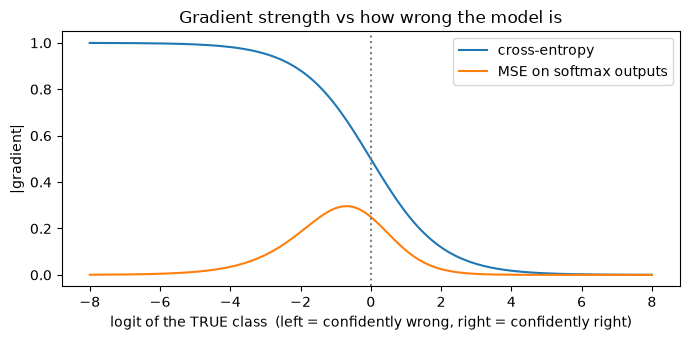

In [7]:
zs = torch.linspace(-8, 8, 161)
grad_ce, grad_mse = [], []
for z in zs:
    z = z.clone().requires_grad_(True)
    logits = torch.stack([z, torch.tensor(0.0)]).unsqueeze(0)
    target = torch.tensor([0])

    ce = F.cross_entropy(logits, target)
    g_ce, = torch.autograd.grad(ce, z)
    grad_ce.append(abs(g_ce.item()))

    z2 = z.detach().clone().requires_grad_(True)
    probs = torch.softmax(torch.stack([z2, torch.tensor(0.0)]).unsqueeze(0), dim=1)
    mse = F.mse_loss(probs, F.one_hot(target, 2).float())
    g_mse, = torch.autograd.grad(mse, z2)
    grad_mse.append(abs(g_mse.item()))

plt.figure(figsize=(7, 3.5))
plt.plot(zs, grad_ce, label="cross-entropy")
plt.plot(zs, grad_mse, label="MSE on softmax outputs")
plt.axvline(0, color="gray", ls=":")
plt.xlabel("logit of the TRUE class  (left = confidently wrong, right = confidently right)")
plt.ylabel("|gradient|")
plt.title("Gradient strength vs how wrong the model is")
plt.legend(); plt.tight_layout(); plt.show()

**What to observe.** On the far left (confidently wrong) cross-entropy keeps a gradient near 1 → the model is told
firmly to fix it. MSE's gradient **collapses toward 0** exactly where the model is most wrong, because softmax
saturates (it is flat when one probability is ~1). A "vanishing gradient" means learning stalls.
Cross-entropy's `-log` exactly cancels softmax's `exp`, leaving the clean gradient `p - y`.

## 4. Label smoothing: do not be 100% sure

With hard targets `[0, 0, 1, 0]` the loss only reaches 0 if the logit of the true class goes to infinity. The
network keeps inflating its logits, becoming over-confident (and often less accurate on new data). **Label smoothing**
softens the target to e.g. `[0.0027, 0.0027, 0.9919, 0.0027]` (PyTorch: `(1-eps) * one_hot + eps / K`).

In [8]:
eps, K = 0.1, 5
logits = torch.randn(6, K) * 2
targets = torch.randint(0, K, (6,))

# Manual version: cross-entropy against the softened target distribution.
log_p = torch.log(softmax(logits))
soft_target = (1 - eps) * F.one_hot(targets, K).float() + eps / K
manual = -(soft_target * log_p).sum(dim=1).mean()

builtin = build_loss("label_smoothing", label_smoothing=eps)(logits, targets)
print("manual :", manual.item())
print("builtin:", builtin.item())
assert torch.allclose(manual, builtin, atol=1e-6)

# Even a *perfectly confident, correct* model has loss > 0 with smoothing -> no incentive for infinite logits.
perfect = torch.full((1, K), -50.0); perfect[0, 2] = 50.0
print("hard CE on a perfect prediction      :", build_loss("cross_entropy")(perfect, torch.tensor([2])).item())
print("smoothed CE on a perfect prediction  :", build_loss("label_smoothing", label_smoothing=eps)(perfect, torch.tensor([2])).item())

manual : 2.5679898262023926
builtin: 2.5679898262023926
hard CE on a perfect prediction      : 0.0
smoothed CE on a perfect prediction  : 8.0


## 5. Focal loss: spend effort on the hard examples

$$\text{FL} = (1 - p_t)^{\gamma} \cdot \text{CE}, \qquad p_t = p_y$$

When the model is already right and confident (`p_t` near 1) the factor `(1 - p_t)^γ` is tiny, so those examples
barely contribute. When it is wrong (`p_t` small) the factor is ~1. `γ = 0` is plain cross-entropy. This helps when
most examples are *easy* and a few are *hard or rare* (class imbalance).

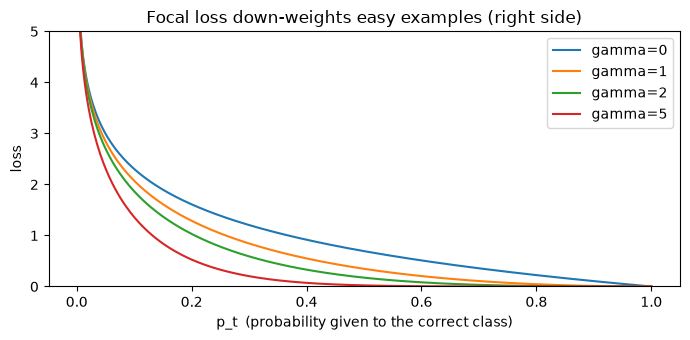

p_t=0.9:  CE=0.105  focal=0.001  (focal keeps 1% of the loss)
p_t=0.1:  CE=2.303  focal=1.865  (focal keeps 81% of the loss)


In [9]:
pt = torch.linspace(0.001, 1, 400)
plt.figure(figsize=(7, 3.5))
for gamma in [0, 1, 2, 5]:
    plt.plot(pt, (1 - pt) ** gamma * -torch.log(pt), label=f"gamma={gamma}")
plt.xlabel("p_t  (probability given to the correct class)"); plt.ylabel("loss")
plt.title("Focal loss down-weights easy examples (right side)"); plt.ylim(0, 5)
plt.legend(); plt.tight_layout(); plt.show()

# An easy example (p_t = 0.9) vs a hard one (p_t = 0.1), gamma = 2:
for p in (0.9, 0.1):
    ce = -math.log(p); fl = (1 - p) ** 2 * ce
    print(f"p_t={p}:  CE={ce:.3f}  focal={fl:.3f}  (focal keeps {fl/ce:.0%} of the loss)")

In [10]:
# Our FocalLoss module equals the formula, and gamma=0 equals plain cross-entropy.
logits = torch.randn(10, 4) * 2
targets = torch.randint(0, 4, (10,))
assert torch.allclose(FocalLoss(gamma=0.0)(logits, targets), nn.CrossEntropyLoss()(logits, targets))
print("focal(gamma=0) == cross-entropy: OK")

focal(gamma=0) == cross-entropy: OK


## Summary

| Loss | One-line idea | Use it when |
|---|---|---|
| `cross_entropy` | `-log(p_correct)` | the default for classification |
| `label_smoothing` | soften the targets | you see over-confident predictions / want better generalisation |
| `focal` | shrink the loss of easy examples | heavy class imbalance, many easy negatives |

All three are in `src/losses.py`, selectable with `--loss` in `src/train.py`.

## Exercises (try them before looking anything up)

1. **Weighted cross-entropy.** Write `weighted_ce(logits, targets, class_weights)` from scratch (multiply each
   example's `-log p_y` by the weight of its class) and compare with `nn.CrossEntropyLoss(weight=...)`.
   (Note PyTorch normalises by the sum of the weights when `reduction="mean"`.)
2. **Temperature.** Divide the logits by a temperature `T` (try 0.5, 1, 3) before `softmax`. What happens to the
   probabilities as `T` grows? As `T → 0`?
3. **Break the sanity check.** Multiply `near_zero_logits` by 100 in the sanity-check cell. Predict the loss before
   running. Why is it so much larger than `ln(K)`?
4. **Which loss for regression** (predicting a price)? Look up MSE vs MAE vs Huber and explain which one is
   robust to outliers and why.